# 1. Data overview

## 1.1. Size and structure of the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from scipy.stats import kruskal

In [2]:
df = pd.read_csv("C:/Users/Felhasználó/Documents/data analysis/risk analysis/data/raw/credit_risk_dataset.csv")

In [3]:
display(df.shape)
display(df.head())

(32581, 12)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


The data is sorted into one 12 x 32581 table. The 12 column names and their meanings are listed below.

* person_age - Age
* person_income - Annual Income
* person_home_ownership - Home ownership
* person_emp_length - Employment length (in years)
* loan_intent - Loan intent
* loan_grade - Loan grade
* loan_amnt - Loan amount
* loan_int_rate - Interest rate
* loan_status - Loan status (0 is non default 1 is default)
* loan_percent_income - Percent income
* cb_person_default_on_file - Historical default
* cb_person_cred_hist_length - Credit history length

Looking at the second row of the dataset we can tell that the person was 21 years old with an annual income of 9600 USD. They owned a house and they have been employed for 5 years at the point they requested loan for education. As for their prior financial behaviour, they had 2 years of credit history recorded altogether in which they did not default. Their loan grade was B suggesting lower risk and more trust from the issuing institution. With a loan amount of 1000 USD and interest rate of 11.14%, the loan took up 10% of their salary. They successfully settled the loan and did not default.

## 1.2. Variables

In [4]:
# Exploring the data

display(df.describe())
df.info()

# Investigating unique categories and their frequencies to examine the consistency of the values

categorical_cols = df.select_dtypes(include="object").columns
for col in categorical_cols:
    print(f"--- Column: {col} ---")
    print(f"{df[col].unique()} \n")


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
--- Column: person_home_ownersh

After taking a closer look to the dataset with some of the most descriptive data quality analysis commands, we can gain a deeper understanding of the data we are working with.
The analysis shows that 8 columns contain numerical values (integer and float data types) out of which the loan_status is a binary feature. 2 of these variables contain null values.

The remaining 4 columns consist of categorical (string) values, of which 1 column is an ordinal while the remaining 3 are nominal variables, containing the cb_person_default_on_file column which is a binary feature. Although binary features are categorical, if coded in a base 2 number system, they can act both like numerical and categorical values. In order to facilitate calculations with the data, 'N' and 'Y' values in the cb_person_default_on_file column will be encoded as 0 and 1 respectively. 
The analysis confirmed that the unique categorical values are consistent and do not contain unknown cells.

It is worth noting, that some categories are relatively underrepresented within the dataset, such as values 'OWN' and 'OTHER' in the person_home_ownership column and the 'Y' group (people with a default history) in the cb_person_default_on_file column. In the loan_grade column there is a monotone, consistent decrease in the number of records as we go from 'A' to 'G', resulting in very few observations in the 'E', 'F' and 'G' categories. This means that patterns discovered in these categories will need to be analysed more carefully than in other, more represented cases.

Descriptive statistical indicators reveal logical inconsistencies in the data, such as the maximum values of the age column (144 years) and employement length column (123 years). Since these are not possible values they cannot be considered outliers, therefore this is most probably a data quality concern. In order to ensure an accurate analysis and a well-working ML algorithm, rows containig invalid data need to be removed.

In the data quality assessment we will be taking a closer look to the identified errors and inconsistencies.

In [5]:
df["cb_person_default_on_file"] = df["cb_person_default_on_file"].replace(to_replace= ["N", "Y"], value= [0, 1])
df[["cb_person_default_on_file", "loan_status"]] = df[["cb_person_default_on_file", "loan_status"]].astype(bool)
df.head()

C:\Users\Felhasználó\AppData\Local\Temp\ipykernel_4388\3058030633.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["cb_person_default_on_file"] = df["cb_person_default_on_file"].replace(to_replace= ["N", "Y"], value= [0, 1])


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,True,0.59,True,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,False,0.10,False,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,True,0.57,False,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,True,0.53,False,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,True,0.55,True,4


Another thing that sticks out is the minimum value of the loan_percent_income column. A 0 in this column would mean that the loan amount takes up 0% of the person's income. Since every client in this dataset is borrower, the problem comes from the variable being calculated and rounded to 2 decimals, resulting in some information loss in the variable. In order to have an even more accurate data, this column will be recalculated.

In [6]:
df["loan_pct_income"] = df["loan_amnt"] / df["person_income"]
df["difference"] = df["loan_percent_income"] - df["loan_pct_income"]
print(f"Information loss due to rounding: \n{df["difference"].describe()}")

df.drop(columns=["loan_percent_income", "difference"], inplace=True)

Information loss due to rounding: 
count    32581.000000
mean        -0.000350
std          0.004926
min         -0.093382
25%         -0.002500
50%          0.000000
75%          0.002500
max          0.005000
Name: difference, dtype: float64


### 1.2.1. Target variable

The main question that this analysis seeks to answer is 'How can we tell ahead of time, if someone is going to default?' or in data terms 'What features and patterns increase the probability of defaulting, if any?'. There is a column in the dataset that tells us which people ended up defaulting and this is the loan_status column. In order to answer the thesis question, the best course of action would be to explore potential correlations in the data with more emphasis on patterns with the loan_status column. We are also going to train an algorithm to spot these correlations in the data with the target variable being the loan_status column.

In [7]:
print(df["loan_status"].value_counts())
print(df["loan_status"].mean())

loan_status
False    25473
True      7108
Name: count, dtype: int64
0.21816396059052823


The target variable consists of 25473 '0' values and 7108 '1' values, meaning that the classes are imbalanced and the default rate of the dataset is 21.8%. While it is possible that this default ratio is closer to the distribution of defaulters in the population than a 50-50 ratio, this could impact the accuracy of the predictive model, therefore it needs to be addressed while looking at the performance of the algorithm.

# 2. Data quality assessment

## 2.1. Missing values and duplicates

In [8]:
# Checking for missing values and potential duplicates

print(df.isnull().sum())
display(df[df.duplicated()])

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
loan_pct_income                  0
dtype: int64


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,cb_person_default_on_file,cb_person_cred_hist_length,loan_pct_income
15975,23,42000,RENT,5.0,VENTURE,B,6000,9.99,False,False,4,0.142857
15989,23,90000,MORTGAGE,7.0,EDUCATION,B,8000,10.36,False,False,3,0.088889
15995,24,48000,MORTGAGE,4.0,MEDICAL,A,4000,5.42,False,False,4,0.083333
16025,24,10000,RENT,8.0,PERSONAL,A,3000,7.90,True,False,3,0.300000
16028,23,100000,MORTGAGE,7.0,EDUCATION,A,15000,7.88,False,False,4,0.150000
...,...,...,...,...,...,...,...,...,...,...,...,...
32010,42,39996,MORTGAGE,2.0,HOMEIMPROVEMENT,A,2500,5.42,False,False,12,0.062506
32047,36,250000,RENT,2.0,DEBTCONSOLIDATION,A,20000,7.88,False,False,17,0.080000
32172,49,120000,MORTGAGE,12.0,MEDICAL,B,12000,10.99,False,False,12,0.100000
32259,39,40000,OWN,4.0,VENTURE,B,1000,10.37,False,False,16,0.025000


Since both data analysis and ML algorithms tend to be sensitive to missing values, we need to investigate where and why they may occur and how we can handle them.
Missing values can be identified in 2 columns of the dataset: 2.7% of the employement length column consist of null values and the loan interest rate column is missing 9.5% of its content.

The reason behind null values being present in the dataset cannot be determined by looking at the data alone and will be considered unknown information. Even though this is not necessarily an issue regarding the quality of the data, null values still need to be replaced with values that the algorithm can also handle. In order to better understand the unknown data, patterns and correlations with missingness will be further investigated in a part focused on missing values.

Due to the limitations that arise from the nature of this dataset, we cannot determine whether identical rows are true duplicates or not. Since duplicates are only observed in 165 rows (~0.5% of the dataset) they will be handled as exact duplicates and will be removed. 

### 2.1.1. Analysis on missingness patterns 

Sometimes missingness occurs in patterns, correlating with other factors in the data suggesting an additional meaning to missingness. Handling missing values without assessing this possibility may make our data lose valuable information and become more biased. In order to make a better decision at how to handle missing data in a way that fits the current dataset, this part aims to identify potential patterns with missingness.

In [9]:
# Looking for patterns in the distribution of the missing data
df["emp_length_missing"] = df["person_emp_length"].isnull()
df["loan_int_missing"] = df["loan_int_rate"].isnull()

print("Co-occurrence analysis of missingness")
display(pd.crosstab(df["emp_length_missing"], df["loan_int_missing"], normalize="all")*100)

print("Demographical and financial profiles of people with missing information")
display(df.groupby(df["emp_length_missing"])[[
    "loan_status", 
    "person_age", 
    "person_income", 
    "loan_amnt", 
    "loan_pct_income",
    "loan_int_rate", 
    "cb_person_cred_hist_length",
    "cb_person_default_on_file"]].agg(
        loan_status=("loan_status", "mean"),
        person_age=("person_age", "median"),
        person_income=("person_income", "median"),
        loan_amnt=("loan_amnt", "median"),
        loan_percent_income=("loan_pct_income", "median"),
        loan_int_rate=("loan_int_rate", "median"),
        cb_person_cred_hist_length=("cb_person_cred_hist_length", "median"),
        cb_person_default_on_file=("cb_person_default_on_file", "mean")
))

display(df.groupby(df["loan_int_missing"])[[
    "loan_status", 
    "person_age", 
    "person_income", 
    "loan_amnt", 
    "loan_pct_income",
    "person_emp_length", 
    "cb_person_cred_hist_length", 
    "cb_person_default_on_file"]].agg(
        loan_status=("loan_status", "mean"),
        person_age=("person_age", "median"),
        person_income=("person_income", "median"),
        loan_amnt=("loan_amnt", "median"),
        loan_percent_income=("loan_pct_income", "median"),
        person_emp_length=("person_emp_length", "median"),
        cb_person_cred_hist_length=("cb_person_cred_hist_length", "median"),
        cb_person_default_on_file=("cb_person_default_on_file", "mean")
))

# Investigating missingness across categorical variables
def crosstab_categories(data, col1, col2, norm):
    display(pd.crosstab(data[col1], data[col2], normalize = norm)*100)

missing_cols = np.array(["emp_length_missing", "loan_int_missing"])
crosstab_values = np.array(["person_home_ownership", "loan_intent", "loan_grade"])
for miss in missing_cols:
    print(f"Missing data distribution of the %s column by categorical variables" % (miss))
    for cat in crosstab_values:
        crosstab_categories(df, cat, miss, norm = "index")


Co-occurrence analysis of missingness


loan_int_missing,False,True
emp_length_missing,,
False,87.897855,9.355146
True,2.538289,0.208711


Demographical and financial profiles of people with missing information


,loan_status,person_age,person_income,loan_amnt,loan_percent_income,loan_int_rate,cb_person_cred_hist_length,cb_person_default_on_file
emp_length_missing,,,,,,,,
False,0.215426,26.0,56000.0,8000.0,0.147115,10.99,4.0,0.177649
True,0.315084,25.0,36000.0,6000.0,0.166667,9.91,4.0,0.129609


,loan_status,person_age,person_income,loan_amnt,loan_percent_income,person_emp_length,cb_person_cred_hist_length,cb_person_default_on_file
loan_int_missing,,,,,,,,
False,0.219379,26.0,55000.0,8000.0,0.147929,4.0,4.0,0.176922
True,0.206675,26.0,55640.0,8000.0,0.150000,4.0,4.0,0.170732


Missing data distribution of the emp_length_missing column by categorical variables


... (3 outputs left out)

Missing data distribution of the loan_int_missing column by categorical variables


loan_int_missing,False,True
person_home_ownership,,
MORTGAGE,90.166617,9.833383
OTHER,87.850467,12.149533
OWN,91.176471,8.823529
RENT,90.556974,9.443026


loan_int_missing,False,True
loan_intent,,
DEBTCONSOLIDATION,90.234075,9.765925
EDUCATION,90.717496,9.282504
HOMEIMPROVEMENT,91.262136,8.737864
MEDICAL,89.787514,10.212486
PERSONAL,90.816881,9.183119
VENTURE,90.103165,9.896835


loan_int_missing,False,True
loan_grade,,
A,90.693143,9.306857
B,89.895704,10.104296
C,90.244658,9.755342
D,91.395477,8.604523
E,91.390041,8.609959
F,88.796680,11.203320
G,92.187500,7.812500


The co-occurrence analysis of missing details shows only 0.2% of joint missingness in the data, suggesting that the occurrence of missing data is mostly separate across the two examined variables.

The missingness of loan_int_rate does not appear to be strongly associated with the target variable or the examined numerical characteristics of the borrowers. On the other hand, employment length missingness shows a noticeable association with some of the observed characteristics of the applicants. Borrowers with missing values have lower median incomes and median loan amounts, while their loan-to-income ratios are slightly higher, and their default rates are also significantly higher. This confirms our initial assumption that the missingness may contain information and should not be treated as completely random.

As for the categorical variables, employment length missingness appears to vary across home ownership categories, with the highest missingness rate observed among applicants with OWN home ownership. In contrast, missingness rates are relatively similar across loan intent categories and show smaller differences across the other categorical variables examined. Loan interest rate missingness does not show a strong or consistent relationship with the categorical variables examined.

### 2.1.2. Missing values handling strategy

When it comes to this specific dataset removing rows with missing information is not a viable option, replacing them would be much more preferable.

Since missing interest rates take up about 9.6% of the observations, removing them could lead to a data loss potentially more harmful to predictive accuracy than imputation. Although imputation reduces the variance of the data, the significance of these values justifies the usage of this method.

During the assessment of the missing data in the employment length column, an underlying pattern surfaced, suggesting that missingness itself carries additional information. The missing values cannot be left empty, therefore median imputation will be performed on this column as well. In order to keep the information that lies behind missingness, the boolean emp_length_missing column (previously used to identify missingness patterns) will be kept to flag values that were originally missing. 

Although the above mentioned strategy is preferred for the purposes of the algorithm, in the aspect of the data analysis, filling the missing values with artificial data might lead to inaccurate insights. Therefore this step will only be done when building the model, missing values here will be handled with code that ignores nans.

## 2.2. Inconsistent values

Invalid values raise a great data quality concern, therefore age and employment length values above a reasonable threshold will also be removed as a next step. Additionally, data that proves to be inaccurate by respective values in the other column (e.g. higher employment length than age) will also be removed.
Assuming that no borrower is past 100 years old and that no borrower started working or received loans before the age of 16, the validity criteria will be the following:

person_age < 100

person_emp_length < person_age – 16

cb_person_cred_hist_length < person_age – 16 

In [10]:
invalid_age = df["person_age"] > 100
invalid_emp = df["person_emp_length"] > df["person_age"]-16 
invalid_hist =df["cb_person_cred_hist_length"]> df["person_age"]-16

print(f"Number of invalid ages: {invalid_age.sum()}")
print(f"Number of invalid employment lengths: {invalid_emp.sum()}")
print(f"Number of invalid credit history lengths: {invalid_hist.sum()}")

Number of invalid ages: 5
Number of invalid employment lengths: 740
Number of invalid credit history lengths: 0


The vast majority of the data deemed logically inconsistent is caused by violating the employment length validity criterium. This could be due to the strictness of the initially set validity criteria. Let's investigate how this data is distributed now. 

In [11]:
df["employment_excess"] = (df["person_emp_length"] - (df["person_age"] - 16))
df.loc[invalid_emp, "employment_excess"].describe(percentiles=[0.9, 0.95, 0.99])

count    740.000000
mean       1.314865
std        6.052503
min        1.000000
50%        1.000000
90%        1.000000
95%        1.000000
99%        1.000000
max      118.000000
Name: employment_excess, dtype: float64

In [12]:
invalid_emp_new = df["person_emp_length"] > df["person_age"]-15
print(f"Number of invalid employment lengths with starting age 15: {invalid_emp_new.sum()}")

Number of invalid employment lengths with starting age 15: 2


The results suggest that loosening the criterium with just 1 year would lead to significantly less data loss. Since starting work at the age of 15 can also be reasonable, the respective validity criterium will be updated to the following:

person_emp_length < person_age – 15

## 2.3. Extreme values and outliers

In [13]:
# Statistical outlier analysis with the Interquantile Range (IQR) method

numeric_cols = df.select_dtypes(include="number")

Q1 = numeric_cols.quantile(.25, axis = 0)
Q3 = numeric_cols.quantile(.75, axis = 0)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers_list = []

for col in numeric_cols.columns:
    for idx, value in numeric_cols[col].items():
        if value < lower_limit[col] or value > upper_limit[col]:
            outliers_list.append({"row": idx, "column": col, "value": value})

outliers_iqr = pd.DataFrame(outliers_list)

outlier_count = outliers_iqr.groupby("column").agg(
    count=("value", "count"),
    min_outlier=("value", "min"),
    max_outlier=("value", "max"),
)

display(outlier_count)

# Measuring the asymmetry of the data distribution across the columns

summary = pd.DataFrame({
    "skew": numeric_cols.skew(),
    "skew_log1p": np.log1p(numeric_cols).skew(),
    "p99": numeric_cols.quantile(0.99),
    "p99.9": numeric_cols.quantile(0.999),
})
print(summary)

,count,min_outlier,max_outlier
column,,,
cb_person_cred_hist_length,1142,16.000000,30.00
employment_excess,989,-124.000000,118.00
loan_amnt,1689,23050.000000,35000.00
loan_int_rate,6,22.060000,23.22
loan_pct_income,733,0.438596,0.83
person_age,1494,41.000000,144.00
person_emp_length,853,15.000000,123.00
person_income,1484,140300.000000,6000000.00


                                 skew  skew_log1p            p99  \
person_age                   2.581393    1.241667      50.000000   
person_income               32.865349    0.155994  225200.000000   
person_emp_length            2.614455   -0.453855      18.000000   
loan_amnt                    1.192477   -0.447506   29800.000000   
loan_int_rate                0.208550   -0.267368      18.620000   
cb_person_cred_hist_length   1.661790    0.487875      17.000000   
loan_pct_income              1.065064    0.818616       0.499968   
employment_excess           -1.663462         NaN       1.000000   

                                    p99.9  
person_age                      66.000000  
person_income               648000.000000  
person_emp_length               25.000000  
loan_amnt                    35000.000000  
loan_int_rate                   20.890000  
cb_person_cred_hist_length      29.000000  
loan_pct_income                  0.633975  
employment_excess                1.

c:\Users\Felhasználó\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: divide by zero encountered in log1p
  result = func(self.values, **kwargs)
c:\Users\Felhasználó\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log1p
  result = func(self.values, **kwargs)
c:\Users\Felhasználó\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\nanops.py:1256: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean


Extreme values - while carrying relevant information - highly and disproportionately impact the statistical characteristics of the data, which needs to be taken into account while deriving information from data. In order to decrease the impact of the deviating values on the models performance, skewed columns will be transformed and columns that contain only a few extremes will be capped.

It is important to note, that impossibly high values are also be returned as statistical outliers. To ensure that only genuinely high values are in the data, outlier assessment will be conducted after the invalid values have aleady been removed.

# 3. Data cleaning and transformation

## 3.1. Data quality enhancement plan

Data cleaning will be conducted in the following order.

1. Duplicates

Since duplicates represent only a small number of records, removing them will not affect the size of the dataset greatly. For reasons of avoiding the risks that exact duplicates may hold, the first step will be removing these rows.

2. Inconsistent values

Carrying these two steps out will result in minimal data loss, however, this trade-off is necessary in order to enhance the reliability and accuracy of the analytic and predictive results.


In [14]:
# New variable on which the cleaning will be done
df_clean = df.drop(columns=["loan_int_missing", "employment_excess", "emp_length_missing"]).copy()
print(f"Dimensions of the data pre-cleaning: {np.shape(df_clean)}")

# Removing duplicate rows
df_clean = df_clean.drop(index=df_clean.index[df_clean.duplicated()])
print(f"Dimensions after removing duplicates: {np.shape(df_clean)}")

# Removing invalid values
invalid_flag = (df_clean["person_age"] > 100) | (df_clean["person_emp_length"] > df_clean["person_age"]-15) | (df_clean["cb_person_cred_hist_length"]> df_clean["person_age"]-16)
df_clean = df_clean.drop(index=df_clean.index[invalid_flag])
print(f"Dimensions after removing invalid values: {np.shape(df_clean)}")

Dimensions of the data pre-cleaning: (32581, 12)
Dimensions after removing duplicates: (32416, 12)
Dimensions after removing invalid values: (32409, 12)


In [15]:
numeric_cols = df_clean.select_dtypes(include="number")
categorical_cols = df_clean.select_dtypes(include="object")
binary_cols = df_clean.select_dtypes(include="bool")

# 4. Data analysis

## 4.1. Univariate analysis

### 4.1.1. Descriptive statistical analysis

In [55]:
display(df_clean.describe(include="object"))

num_describe = df_clean.describe().apply(lambda s: s.apply("{0:.5f}".format))
num_describe = num_describe.T
num_describe["range"] = numeric_cols.max() - numeric_cols.min()
num_describe["mean_median_difference"] = numeric_cols.mean() - numeric_cols.median()
num_describe["skewness"] = numeric_cols.skew()
num_describe = num_describe.T

display(num_describe)


,person_home_ownership,loan_intent,loan_grade
count,32409,32409,32409
unique,4,6,7
top,RENT,EDUCATION,A
freq,16374,6409,10702


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,cb_person_cred_hist_length,loan_pct_income
count,32409.00000,32409.00000,31522.00000,32409.00000,29315.00000,32409.00000,32409.00000
mean,27.73075,65894.27705,4.78285,9592.48665,11.01710,5.81119,0.17060
std,6.21045,52517.86997,4.03734,6320.88513,3.24172,4.05790,0.10705
min,20.00000,4000.00000,0.00000,500.00000,5.42000,2.00000,0.00079
25%,23.00000,38500.00000,2.00000,5000.00000,7.90000,3.00000,0.08972
50%,26.00000,55000.00000,4.00000,8000.00000,10.99000,4.00000,0.14815
75%,30.00000,79200.00000,7.00000,12250.00000,13.47000,8.00000,0.22917
max,94.00000,2039784.00000,41.00000,35000.00000,23.22000,30.00000,0.83000
range,74.0,2035784.0,41.0,34500.0,17.8,28.0,0.829211
mean_median_difference,1.730754,10894.277053,0.78285,1592.486655,0.027099,1.811194,0.022448


The descriptive table above summarizes the main features of the dataset after cleaning. These features include central tendency, variability and skewness. The skewness value shows that loan_int_rate is normally distributed, while all other numerical columns are strongly skewed. The differences between the mean and median values suggest that the mentioned columns are right-skewed.

The max values reveal data that seem to highly deviate from the respective central values, suggesting the presence of outliers that may play a role in the asymmetry of the data distribution. 

In [49]:
display(df_clean.describe(include="object"))
bool_describe = pd.DataFrame({
    "count": binary_cols.count(),
    "mean": binary_cols.mean()
})
display(bool_describe.transpose())

,person_home_ownership,loan_intent,loan_grade
count,32409,32409,32409
unique,4,6,7
top,RENT,EDUCATION,A
freq,16374,6409,10702


,loan_status,cb_person_default_on_file
count,32409.000000,32409.000000
mean,0.218705,0.176772


### 4.1.2. Outliers

Extreme values - while carrying relevant information - highly and disproportionately impact the statistical characteristics of the data, which needs to be taken into account while deriving insights from data. Let's assess the outliers in the numerical variables with the IQR method. 

* Q1 = 1st quantile
* Q3 = 3rd quantile
* IQR = Q3 - Q1
* Lower limit (values below will be returned as outliers): Q1 - 1.5 * IQR
* Upper limit (values above will be returned as outliers): Q3 + 1.5 * IQR

It is important to note, that impossibly high values would also be returned as statistical outliers. To ensure that only genuinely high values are in the data, outlier assessment is conducted after the invalid values have aleady been removed. 

In [72]:
Q1 = numeric_cols.quantile(.25, axis = 0)
Q3 = numeric_cols.quantile(.75, axis = 0)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers_list = []

for col in numeric_cols.columns:
    for idx, value in numeric_cols[col].items():
        if value < lower_limit[col] or value > upper_limit[col]:
            outliers_list.append({"row": idx, "column": col, "value": value})

outliers_iqr = pd.DataFrame(outliers_list).set_index("row")

outlier_summary = outliers_iqr.groupby("column").agg(
    count=("value", "count"),
    min_outlier=("value", "min"),
    max_outlier=("value", "max")
)

outliers_pct_list = []

for col in numeric_cols.columns:
    pct = outlier_summary.loc[col]["count"] / numeric_cols[col].count() * 100
    outliers_pct_list.append({"idx": col, "pct": pct, "upper_limit": upper_limit[col]})

outliers_pct = pd.DataFrame(outliers_pct_list).set_index("idx")
outlier_summary = pd.concat([outlier_summary, outliers_pct], axis = 1)

display(outlier_summary)

,count,min_outlier,max_outlier,pct,upper_limit
cb_person_cred_hist_length,1138,16.000000,30.00,3.511370,15.500000
loan_amnt,1678,23200.000000,35000.00,5.177574,23125.000000
loan_int_rate,6,22.060000,23.22,0.020467,21.825000
loan_pct_income,732,0.438356,0.83,2.258632,0.438333
person_age,1486,41.000000,94.00,4.585146,40.500000
person_emp_length,850,15.000000,41.00,2.696529,14.500000
person_income,1474,140300.000000,2039784.00,4.548119,140250.000000


Judging by the minimum value, all outliers are returned because of surpassing the upper_limit of the IQR method, suggesting that these values contribute to skewing the data to the right. Extreme values take up between 2.3% and 5.1% of strongly skewed columns. There is no evidence indicating the inaccuracy of these values, therefore their removal would lead to the loss of relevant information. However, if not removed, extreme values run the risk of distorting indicators and certain visualisations, while also adversely impacting the accuracy of statistical methods and machine learning algorithms. 

In order to balance these negative effects, data skewness will be taken into account while choosing further analysis methods and outliers will be filtered out from impacted visualisations.

As for decreasing the impact of deviating values and skewness on the model's performance, skewed columns will be transformed and columns that only contain a few extremes will be capped in the data used for training the algorithm.

### 4.1.3. Data distribution

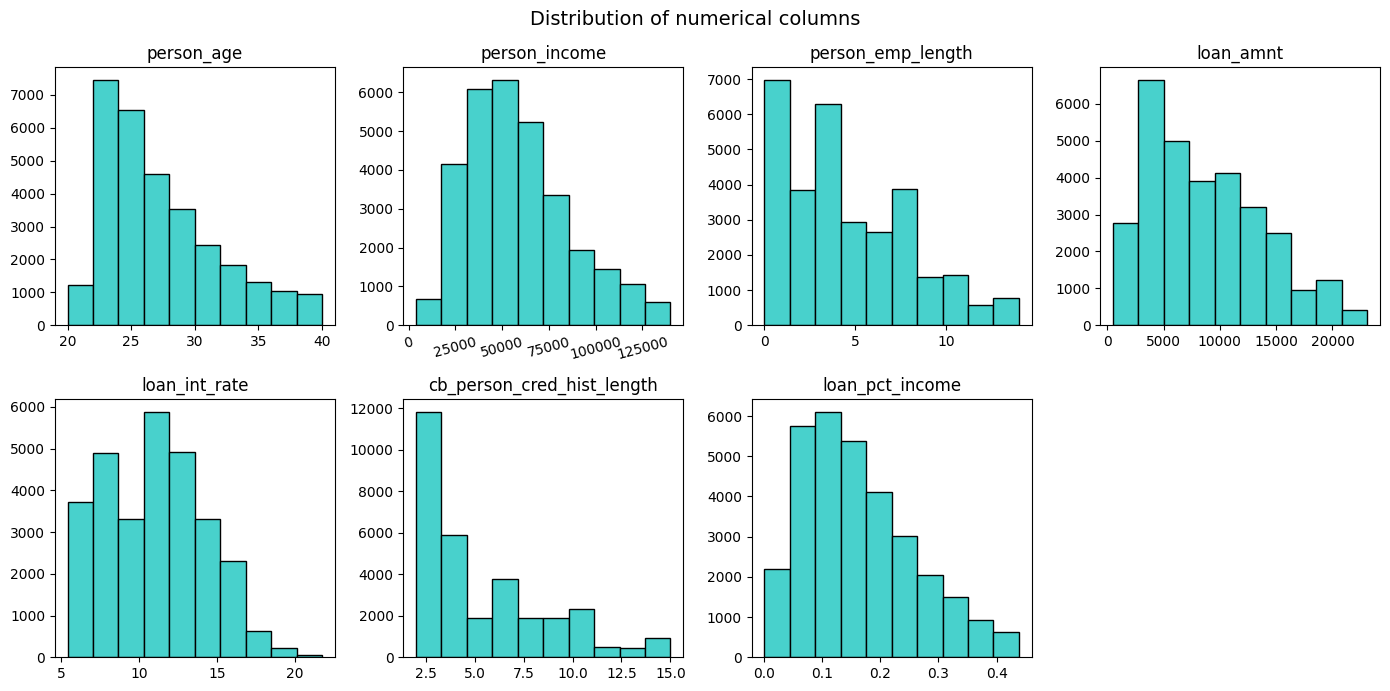

In [ ]:
cols = numeric_cols.columns

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()
plt.ticklabel_format(style='plain')

for ax, col in zip(axes, cols):
    outlier = outliers_iqr.loc[outliers_iqr["column"] == col]
    outlier_index = outlier.index
    num_distribution = numeric_cols.drop(index=outlier_index)
    ax.hist(num_distribution[col].dropna(), bins=10, color='mediumturquoise', edgecolor='black')
    if col == "person_income":
            ax.tick_params(axis='x', labelrotation=15)
    ax.set_title(col)

for ax in axes[len(cols):]:
    ax.set_visible(False)

fig.suptitle("Distribution of numerical columns", fontsize=14)
plt.tight_layout()
plt.show()

c:\Users\Felhasználó\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\fromnumeric.py:54: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return bound(*args, **kwds)


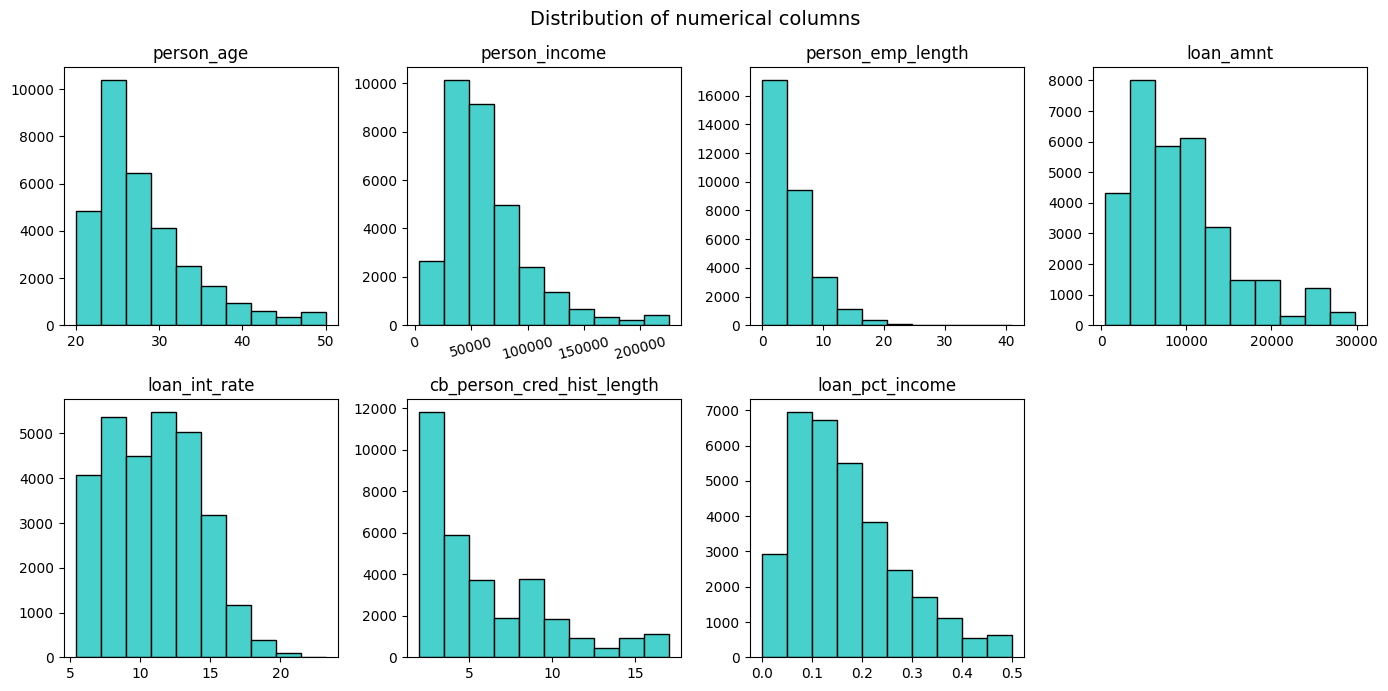

In [74]:

cols = numeric_cols.columns

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()
plt.ticklabel_format(style='plain')

for ax, col in zip(axes, cols):
    capped = np.clip(a = numeric_cols[col], a_min = None, a_max = np.quantile(numeric_cols[col], 0.99))
    ax.hist(capped.dropna(), bins=10, color='mediumturquoise', edgecolor='black')
    if col == "person_income":
            ax.tick_params(axis='x', labelrotation=15)
    ax.set_title(col)

for ax in axes[len(cols):]:
    ax.set_visible(False)

fig.suptitle("Distribution of numerical columns", fontsize=14)
plt.tight_layout()
plt.show()

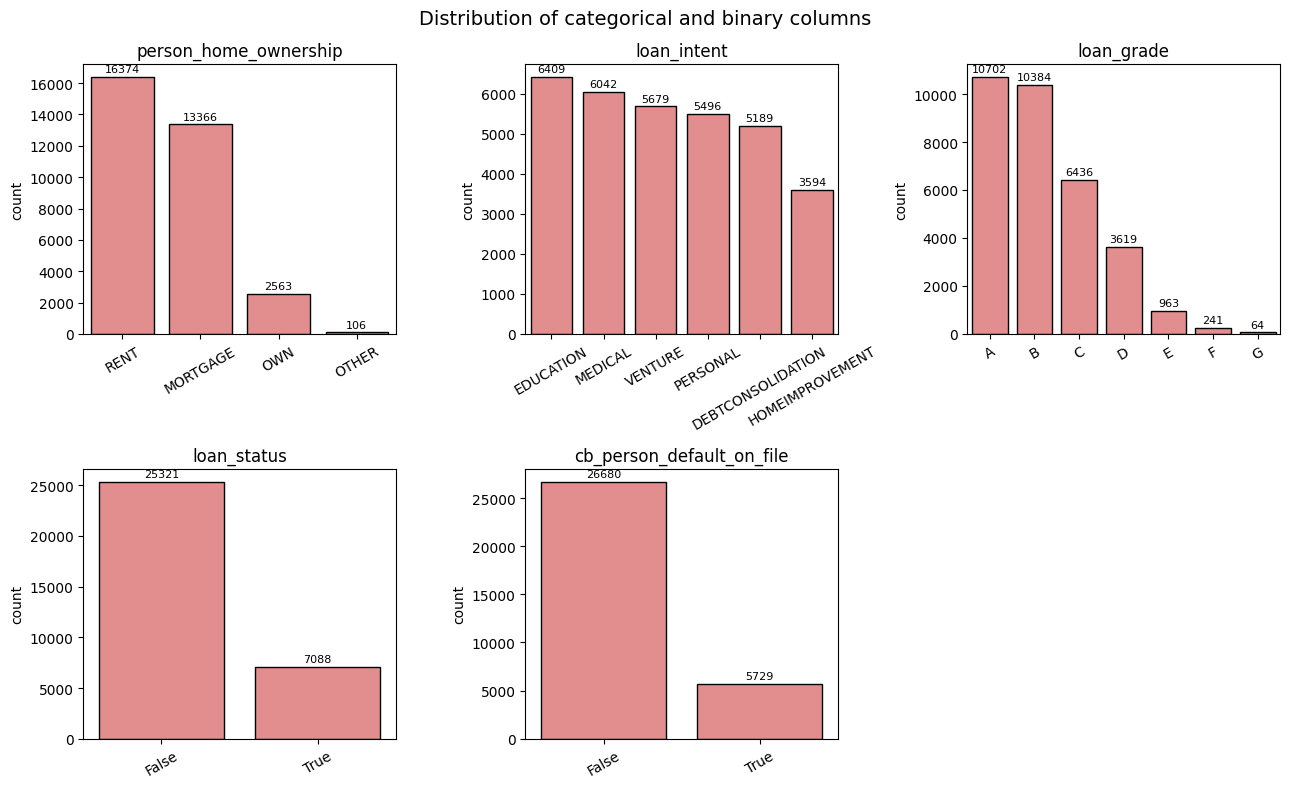

In [81]:
cat_bool_cols = categorical_cols.columns.append(binary_cols.columns)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for ax, col in zip(axes, cat_bool_cols):
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, x=col, order=order, color="lightcoral", edgecolor="black", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=30)
    ax.bar_label(ax.containers[0], fontsize=8, padding=2)

for ax in axes[len(cat_bool_cols):]:
    ax.set_visible(False)

fig.suptitle("Distribution of categorical and binary columns", fontsize=14)
plt.tight_layout()
plt.show()


## 4.2. Bivariate and multivariate analysis

### 4.2.1. Numerical vs. numerical

<Axes: >

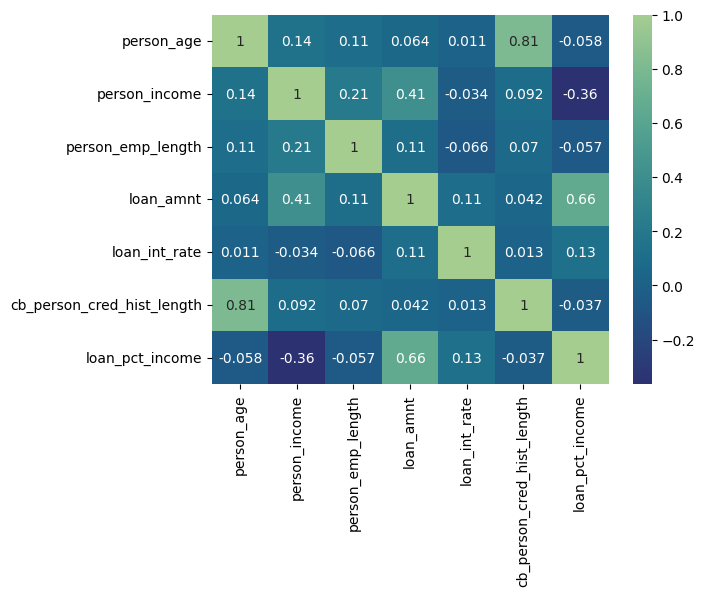

In [96]:
num_correlation = numeric_cols.corr(method="spearman")
sns.heatmap(num_correlation, annot=True, cmap = "crest_r")

Text(0, 0.5, 'Credit history length')

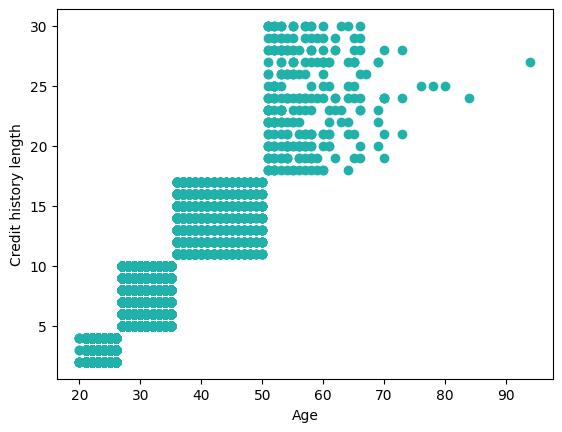

In [103]:
plt.scatter(df_clean["person_age"], df_clean["cb_person_cred_hist_length"], c="lightseagreen")
plt.xlabel("Age")
plt.ylabel("Credit history length")

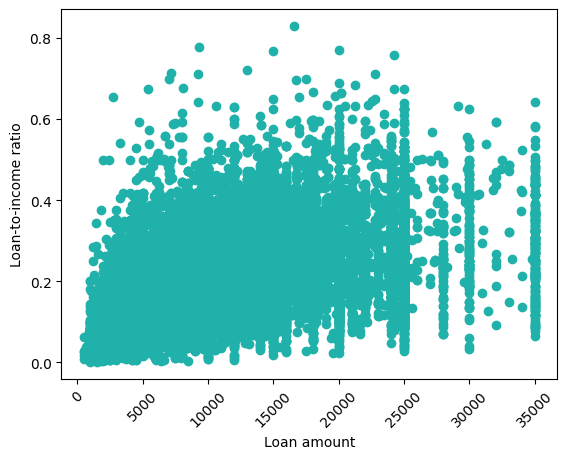

In [105]:
plt.scatter(df_clean["loan_amnt"], df_clean["loan_pct_income"], c="lightseagreen")
plt.xlabel("Loan amount")
plt.ylabel("Loan-to-income ratio")
plt.ticklabel_format(style='plain')
plt.tick_params(axis='x', labelrotation=45)

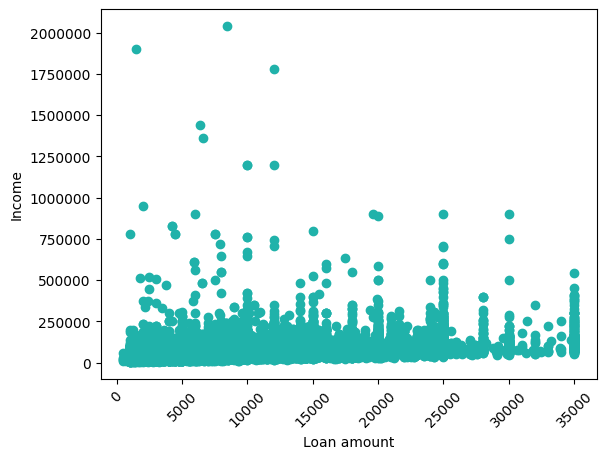

In [ ]:
plt.scatter(df_clean["loan_amnt"], df_clean["person_income"], c="lightseagreen")
plt.xlabel("Loan amount")
plt.ylabel("Income")
plt.ticklabel_format(style='plain')
plt.tick_params(axis='x', labelrotation=45)

### 4.2.2. Categorical vs. numerical

,person_home_ownership,loan_intent,loan_grade
person_age,0.003,0.026,0.000
person_income,0.119,0.010,0.004
person_emp_length,0.064,0.001,0.005
loan_amnt,0.016,0.002,0.020
loan_int_rate,0.022,0.001,0.898
cb_person_cred_hist_length,0.001,0.011,0.000
loan_pct_income,0.021,0.001,0.021


<Axes: >

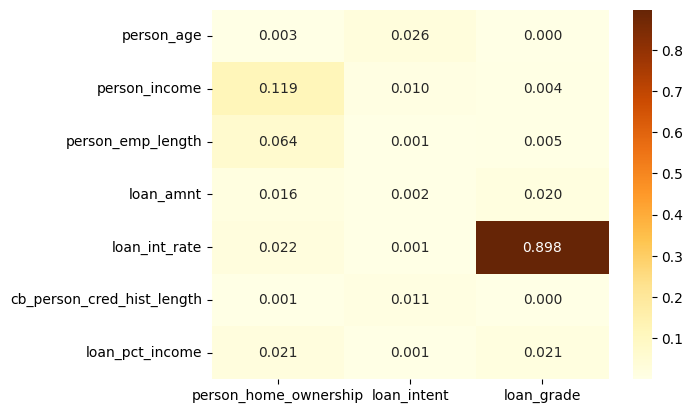

In [95]:
headers = []
indices = []
kruskal_list = []

for col1 in categorical_cols:
    headers.append(col1)
    for col2 in numeric_cols:
        if col2 not in indices:
            indices.append(col2)
        groups = [group[col2].values for name, group in df_clean.groupby(col1)]
        statistic, pval = kruskal(*groups)
        kruskal_list.append(pval)

kruskal_list = pd.DataFrame(kruskal_list)
kruskal_table = pd.DataFrame(kruskal_list.values.reshape(7, 3), index = indices, columns = headers)
#display(kruskal_table.style.format("{:.6f}"))

#sns.heatmap(kruskal_table, annot=True, fmt = ".4f", cmap="Blues")

effect = {}
for cat in categorical_cols:
    effect[cat] = {}
    for num in numeric_cols:
        groups = [g[num].dropna().values for _, g in df_clean.groupby(cat)]
        groups = [g for g in groups if len(g) > 0]
        H = kruskal(*groups).statistic
        n = sum(len(g) for g in groups)
        effect[cat][num] = H / (n - 1)

effect_table = pd.DataFrame(effect)
display(effect_table.style.format("{:.3f}").background_gradient(cmap="Blues"))
sns.heatmap(effect_table, annot=True, fmt = ".3f", cmap="YlOrBr")

In [22]:
results = {}
for cat in categorical_cols:
    results[cat] = {}
    for num in numeric_cols:
        groups = [g[num].dropna().values for _, g in df_clean.groupby(cat)]
        results[cat][num] = kruskal(*groups, nan_policy="omit").pvalue

kruskal_table = pd.DataFrame(results)
display(kruskal_table.style.format("{:.2e}"))

,person_home_ownership,loan_intent,loan_grade
person_age,6.29e-21,7.03e-183,1.40e-01
person_income,0.00e+00,4.39e-71,3.47e-25
person_emp_length,0.00e+00,5.01e-06,2.05e-28
loan_amnt,5.38e-111,1.70e-13,4.65e-135
loan_int_rate,1.35e-137,1.04e-02,0.00e+00
loan_percent_income,2.67e-152,1.34e-02,7.68e-135
cb_person_cred_hist_length,1.91e-10,3.07e-76,1.76e-01


<Axes: xlabel='loan_intent', ylabel='person_income'>

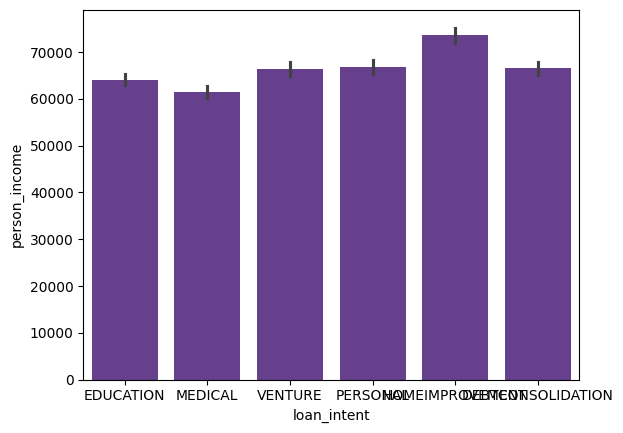

In [ ]:
sns.barplot(data=df_clean, x="loan_intent", y="person_income", color="rebeccapurple")

<Axes: xlabel='loan_grade', ylabel='loan_int_rate'>

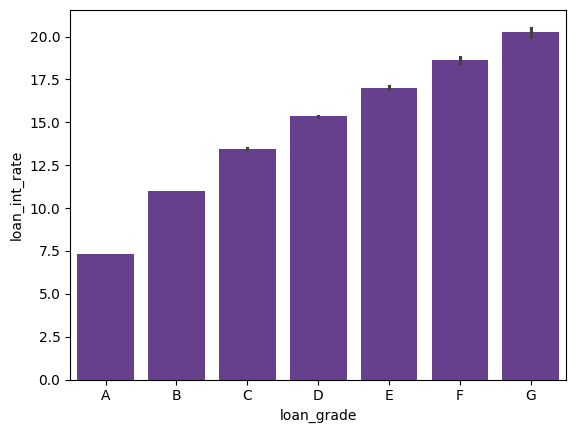

In [48]:
sns.barplot(data=df_clean, x="loan_grade", y="loan_int_rate", order=sorted(df_clean["loan_grade"].unique()), color="rebeccapurple")

<Axes: xlabel='loan_grade', ylabel='loan_int_rate'>

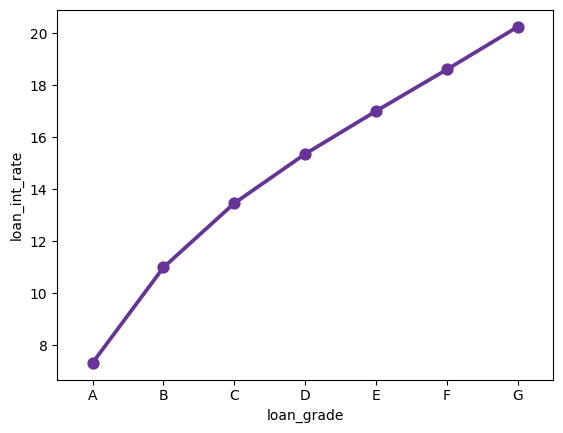

In [49]:
sns.pointplot(data=df_clean, x="loan_grade", y="loan_int_rate", order=sorted(df_clean["loan_grade"].unique()), errorbar=None, color="rebeccapurple")

### 4.2.3. Categorical vs. categorical

,person_home_ownership,loan_intent,loan_grade,loan_status,cb_person_default_on_file
person_home_ownership,0.000000,0.000000,0.000000,0.000000,0.000000
loan_intent,0.000000,0.000000,0.000004,0.000000,0.110510
loan_grade,0.000000,0.000004,0.000000,0.000000,0.000000
loan_status,0.000000,0.000000,0.000000,0.000000,0.000000
cb_person_default_on_file,0.000000,0.110510,0.000000,0.000000,0.000000


Text(0.5, 0.98, 'Strength of association between categorical variables')

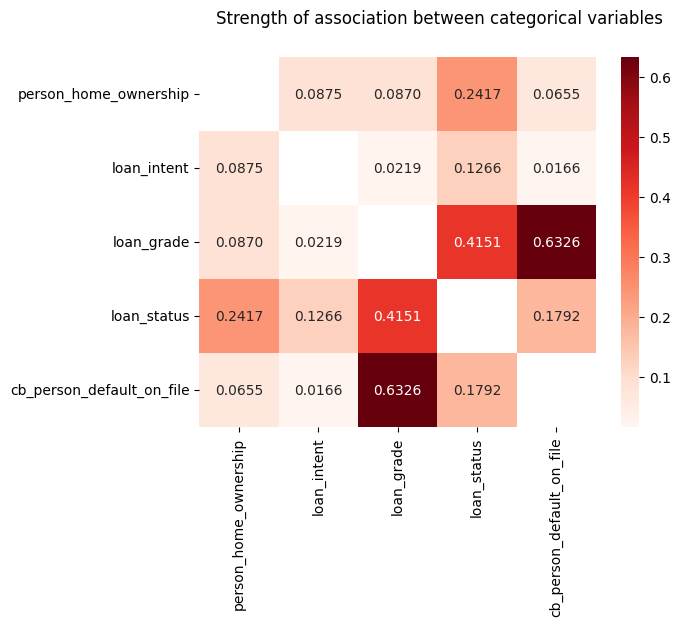

In [ ]:
headers = []
indices = []
chi_list = []
cramer_v = []
for col1 in cat_bool_cols:
    headers.append(col1)
    for col2 in cols:
        crosstab = pd.crosstab(df_clean[col1], df_clean[col2])
        stat, pvalue, dof, exp = chi2_contingency(crosstab)
        chi_list.append((pvalue))
        cramer_v.append(association(crosstab, method = "cramer"))
        if col2 not in indices:
            indices.append(col2)

chi_list = pd.DataFrame(chi_list)
chi_table = pd.DataFrame(chi_list.values.reshape(5, 5), index = indices, columns = headers)
display(chi_table.style.format("{:.6f}"))

cramer_v = pd.DataFrame(cramer_v)
cramer_table = pd.DataFrame(cramer_v.values.reshape(5, 5), index = indices, columns = headers)

sns.heatmap(cramer_table, annot=True, fmt=".4f", cmap="Reds", mask=np.eye(len(cols), dtype=bool))
plt.suptitle("Strength of association between categorical variables")


,person_home_ownership,loan_intent,loan_grade,loan_status,cb_person_default_on_file
person_home_ownership,0.00e+00,5.16e-149,1.11e-144,0.00e+00,6.48e-30
loan_intent,5.16e-149,0.00e+00,4.00e-06,4.63e-110,1.11e-01
loan_grade,1.11e-144,4.00e-06,0.00e+00,0.00e+00,0.00e+00
loan_status,0.00e+00,4.63e-110,0.00e+00,0.00e+00,3.42e-228
cb_person_default_on_file,6.48e-30,1.11e-01,0.00e+00,3.42e-228,0.00e+00


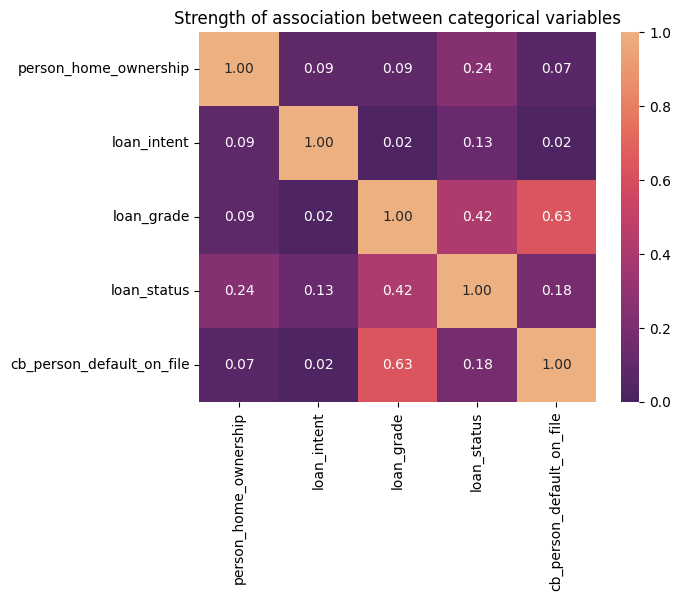

In [90]:
chi_table = pd.DataFrame(index=cat_bool_cols, columns=cat_bool_cols, dtype=float)
cramer_table = pd.DataFrame(index=cat_bool_cols, columns=cat_bool_cols, dtype=float)

for col1 in cat_bool_cols:
    for col2 in cat_bool_cols:
        ct = pd.crosstab(df_clean[col1], df_clean[col2])
        chi_table.loc[col1, col2] = chi2_contingency(ct).pvalue
        cramer_table.loc[col1, col2] = association(ct, method="cramer")

display(chi_table.style.format("{:.2e}"))

sns.heatmap(cramer_table, annot=True, fmt=".2f", cmap="flare_r", vmin=0, vmax=1)
plt.title("Strength of association between categorical variables")
plt.show()

<Axes: xlabel='loan_grade', ylabel='count'>

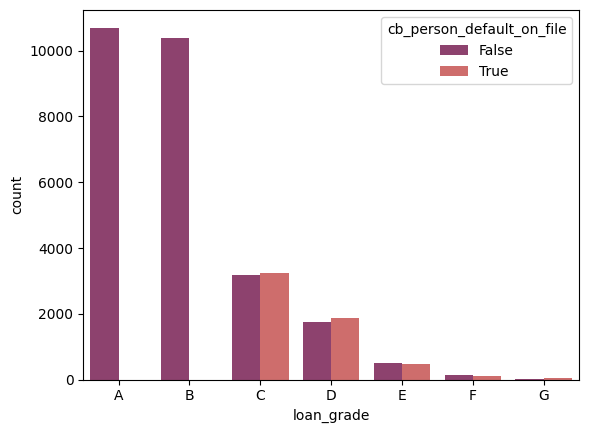

In [100]:
sns.countplot(x="loan_grade", hue="cb_person_default_on_file", data=df_clean, order=sorted(df_clean["loan_grade"].unique()), palette="flare_r")

<Axes: xlabel='loan_grade', ylabel='count'>

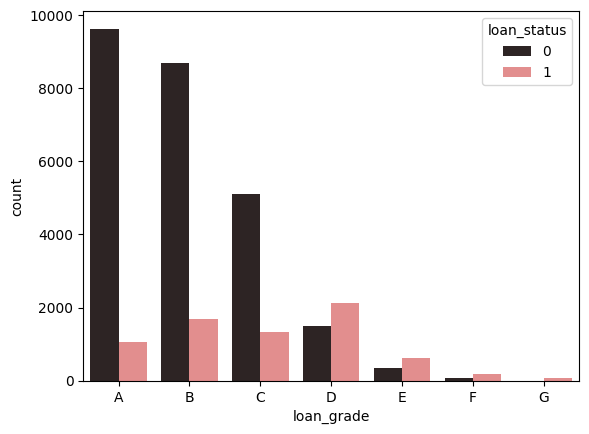

In [55]:
sns.countplot(x="loan_grade", hue="loan_status", data=df_clean, order=sorted(df_clean["loan_grade"].unique()), palette="dark:lightcoral")

<Axes: xlabel='person_home_ownership', ylabel='count'>

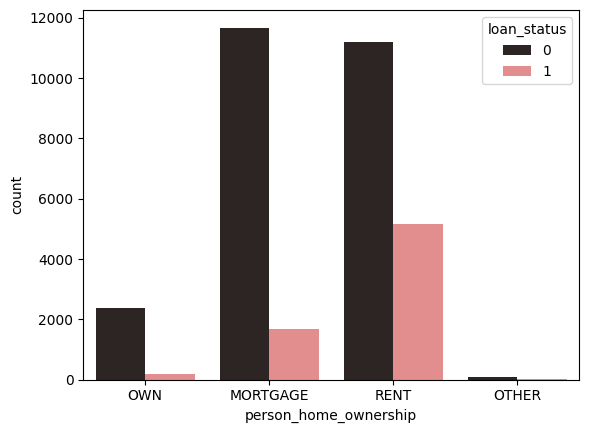

In [56]:
sns.countplot(x="person_home_ownership", hue="loan_status", data=df_clean, palette="dark:lightcoral")